# EDA — Análise Exploratória da Solana

**Encontros 5-6** do projeto integrador de Aprendizagem de Máquina.

Este notebook explora a série diária da Solana (`data/processed/precos_limpo.parquet`,
saída do `preprocess.py`) antes de qualquer modelagem. O objetivo não é prever nada
aqui, e sim **entender a estrutura do dado** — o que ele tem e o que ele não tem.

> **Trabalho acadêmico.** Nada neste notebook é recomendação de investimento. As
> análises descrevem o período coletado e não implicam comportamento futuro.

## Pergunta que guia a exploração

A tarefa de modelagem do projeto é classificar a **direção** do dia seguinte. Vale
perguntar antes: *a série carrega informação sobre direção?* A EDA responde isso —
e a resposta muda como os resultados da classificação devem ser lidos.


In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# funciona tanto rodando de notebooks/ quanto da raiz do projeto
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# série limpa (uma linha por dia, sem lacunas)
precos = pd.read_parquet(RAIZ / "data/processed/precos_limpo.parquet").set_index("data")
preco = precos["preco"]
ret = (preco / preco.shift(1) - 1).dropna()          # retorno diário simples

# atributos e regimes já calculados pelas outras etapas
atributos = pd.read_parquet(RAIZ / "data/processed/atributos.parquet").set_index("data")
regimes = pd.read_parquet(RAIZ / "data/processed/regimes.parquet").set_index("data")

print(f"{len(preco)} dias, de {preco.index.min().date()} a {preco.index.max().date()}")
print(f"preço: {preco.iloc[0]:.2f} -> {preco.iloc[-1]:.2f} USD "
      f"({preco.iloc[-1] / preco.iloc[0] - 1:+.1%} no período)")

365 dias, de 2025-09-01 a 2026-08-31
preço: 200.23 -> 101.68 USD (-49.2% no período)


---
## 1. A série de preços — por que a escala log importa

Duas visões da mesma série: escala linear (o que aconteceu com o valor) e escala
logarítmica (o que aconteceu com as *variações proporcionais*).

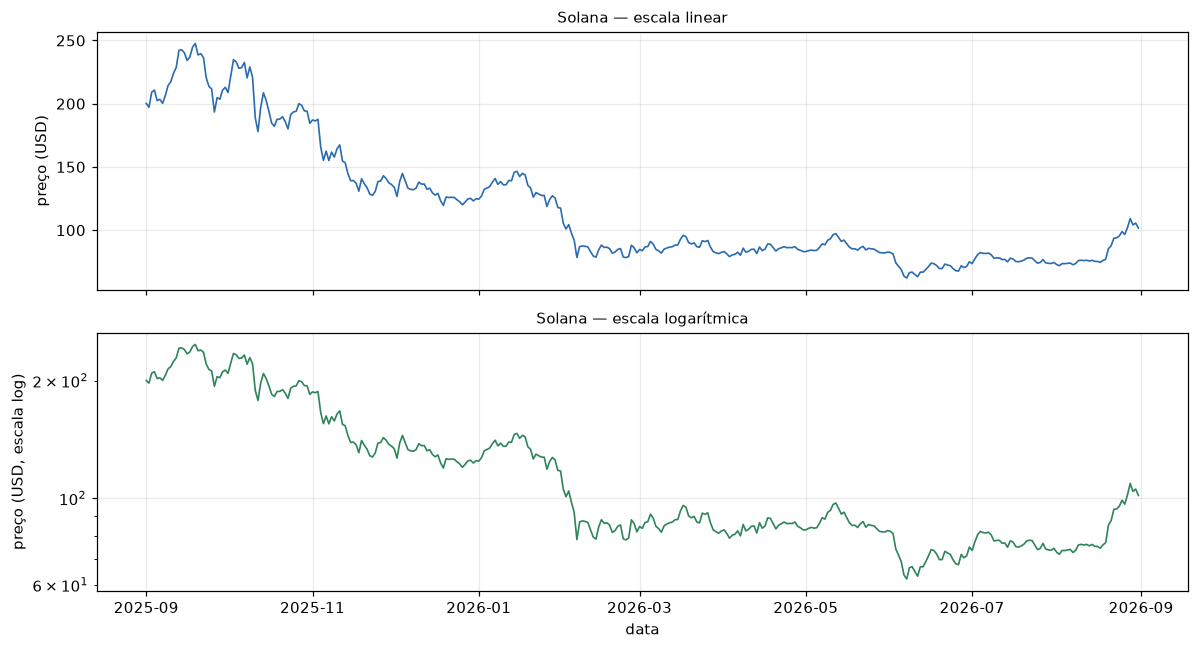

máximo: 247.60 em 2025-09-19
mínimo: 62.18 em 2026-06-07
queda do topo ao fundo: -74.9%


In [2]:
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

a.plot(preco.index, preco.values, color="#2b6cb0", linewidth=1.1)
a.set_ylabel("preço (USD)")
a.set_title("Solana — escala linear", fontsize=10)

b.semilogy(preco.index, preco.values, color="#2f855a", linewidth=1.1)
b.set_ylabel("preço (USD, escala log)")
b.set_title("Solana — escala logarítmica", fontsize=10)
b.set_xlabel("data")

fig.tight_layout()
plt.show()

print(f"máximo: {preco.max():.2f} em {preco.idxmax().date()}")
print(f"mínimo: {preco.min():.2f} em {preco.idxmin().date()}")
print(f"queda do topo ao fundo: {preco.min() / preco.max() - 1:.1%}")

### Interpretação

O período coletado é de **queda acentuada**: de 200,23 para 101,68 USD (−49,2%), com
topo em 247,60 (19/09/2025) e fundo em 62,18 (07/06/2026) — do topo ao fundo, −74,9%.

A escala log é o que torna a série comparável ao longo do tempo. Na escala linear, a
queda de 240 para 200 USD *parece* muito maior que a de 80 para 66, mas ambas são
aproximadamente −17%. Como todo o resto da análise trabalha com **retornos**
(variações proporcionais), a leitura log é a que corresponde ao que os modelos veem.

Uma consequência prática: **o período tem viés de baixa**. Qualquer conclusão sobre
regimes ou classificação vale para um mercado em queda, e não deve ser estendida a
um mercado de alta sem nova verificação.

---
## 2. Distribuição dos retornos diários — as caudas são pesadas?

A suposição de normalidade está por trás de muitos métodos estatísticos. Vale testar
se ela se sustenta aqui.

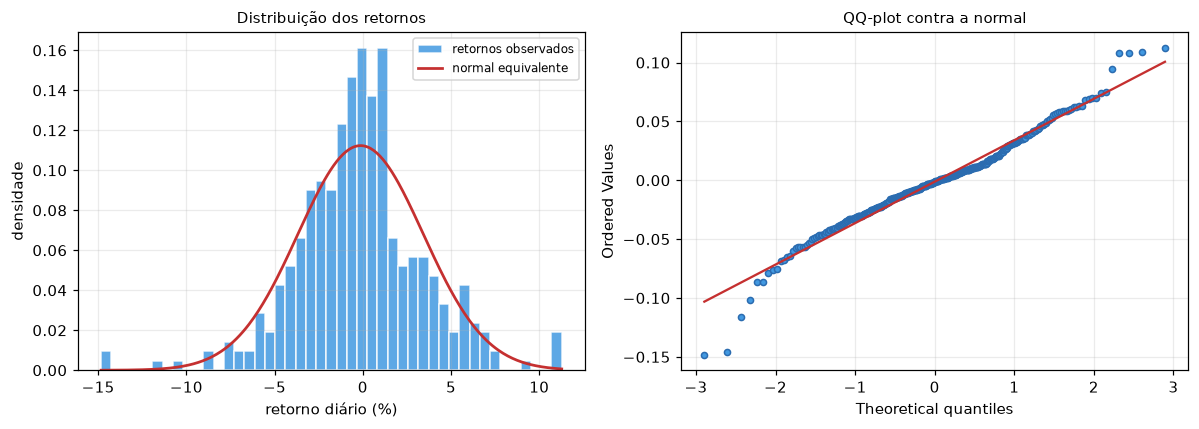

média -0.1227%   mediana -0.1359%   desvio-padrão 3.5516%
assimetria -0.110   curtose em excesso +1.942   (normal = 0)
pior dia -14.83% (2026-02-06)   melhor dia +11.27% (2026-02-26)

Jarque-Bera: p-valor = 9.28e-13 -> rejeita normalidade

frequência de eventos extremos (observado vs esperado sob normalidade):
   |retorno| > 2 desvios:  4.40% vs  4.55%  (  1.0x)
   |retorno| > 3 desvios:  1.92% vs  0.27%  (  7.1x)
   |retorno| > 4 desvios:  0.55% vs  0.01%  ( 86.7x)


In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))

# histograma com a normal de mesma média e desvio sobreposta
a.hist(ret * 100, bins=45, density=True, color="#4299e1",
       edgecolor="white", alpha=0.85, label="retornos observados")
x = np.linspace(ret.min() * 100, ret.max() * 100, 300)
a.plot(x, stats.norm.pdf(x, ret.mean() * 100, ret.std() * 100),
       color="#c53030", linewidth=1.8, label="normal equivalente")
a.set_xlabel("retorno diário (%)")
a.set_ylabel("densidade")
a.set_title("Distribuição dos retornos", fontsize=10)
a.legend(fontsize=8)

# QQ-plot: desvios nas pontas revelam caudas pesadas
stats.probplot(ret, dist="norm", plot=b)
b.get_lines()[0].set_markerfacecolor("#4299e1")
b.get_lines()[0].set_markeredgecolor("#2b6cb0")
b.get_lines()[0].set_markersize(4)
b.get_lines()[1].set_color("#c53030")
b.set_title("QQ-plot contra a normal", fontsize=10)

fig.tight_layout()
plt.show()

print(f"média {ret.mean():+.4%}   mediana {ret.median():+.4%}   desvio-padrão {ret.std():.4%}")
print(f"assimetria {ret.skew():+.3f}   curtose em excesso {ret.kurt():+.3f}   (normal = 0)")
print(f"pior dia {ret.min():+.2%} ({ret.idxmin().date()})   "
      f"melhor dia {ret.max():+.2%} ({ret.idxmax().date()})")

jb = stats.jarque_bera(ret)
print(f"\nJarque-Bera: p-valor = {jb.pvalue:.2e} -> "
      f"{'rejeita normalidade' if jb.pvalue < 0.05 else 'não rejeita'}")

print("\nfrequência de eventos extremos (observado vs esperado sob normalidade):")
for s in (2, 3, 4):
    obs = (ret.abs() > s * ret.std()).mean()
    esp = 2 * (1 - stats.norm.cdf(s))
    print(f"   |retorno| > {s} desvios: {obs:6.2%} vs {esp:6.2%}  ({obs / esp:5.1f}x)")

### Interpretação

Os retornos **não são normais** — Jarque-Bera devolve p ≈ 9×10⁻¹³, uma rejeição
categórica. A curtose em excesso é **+1,94** (a normal tem 0): a distribuição é mais
"pontuda" no centro e com caudas mais pesadas.

O detalhe mais interessante está na tabela de extremos:

| limiar | observado | esperado (normal) | razão |
|---|---|---|---|
| >2 desvios | 4,40% | 4,55% | **1,0x** |
| >3 desvios | 1,92% | 0,27% | **7,1x** |
| >4 desvios | 0,55% | 0,01% | **86,7x** |

Em 2 desvios a normal acerta. O descolamento aparece só nas pontas: eventos de 4
desvios são **87 vezes** mais frequentes que a normal preveria. É a assinatura
clássica de caudas pesadas em ativos financeiros — o risco não está no dia comum,
está nos poucos dias extremos (−14,8% em 06/02/2026, +11,3% em 26/02/2026).

**Consequência para a modelagem:** métodos que assumem normalidade implicitamente
(como o Naive Bayes gaussiano usado na classificação) trabalham com uma suposição
violada. Isso ajuda a explicar por que ele foi o pior classificador do projeto.

---
## 3. Volatilidade ao longo do tempo — ela é constante?

Se a volatilidade fosse constante, a série seria homocedástica e um único desvio-padrão
descreveria o risco. Vamos ver.

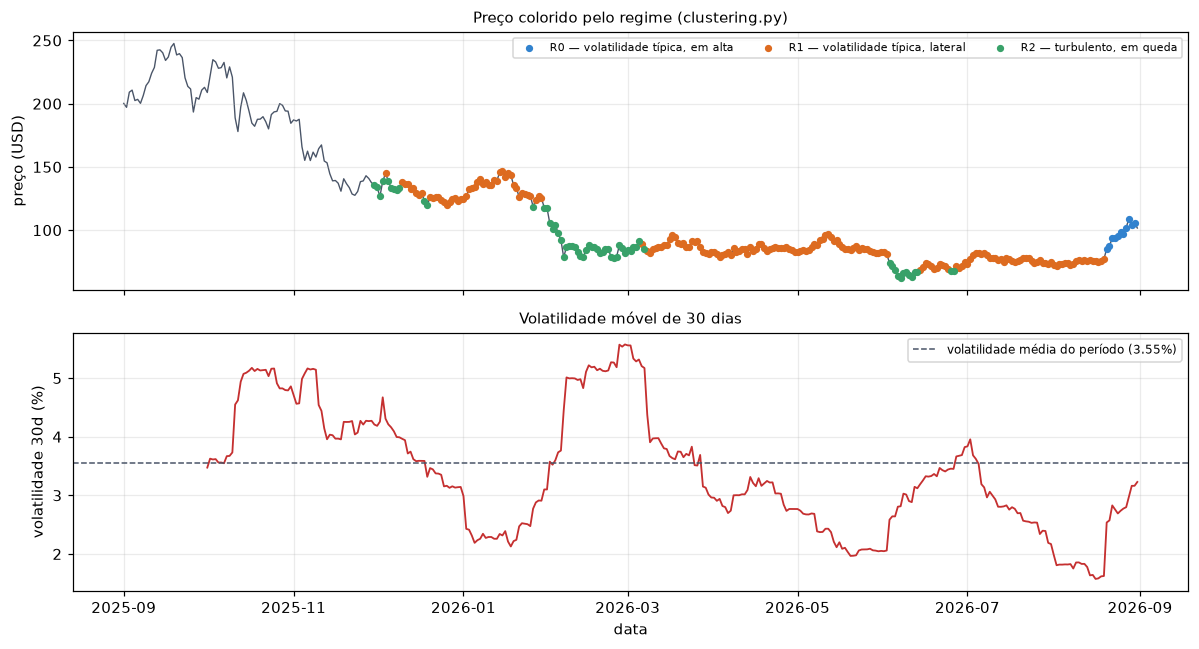

volatilidade 30d: mínima 1.57%  mediana 3.21%  máxima 5.57%
razão máxima/mínima: 3.5x


In [4]:
vol30 = ret.rolling(30).std()

fig, (a, b) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

a.plot(preco.index, preco.values, color="#4a5568", linewidth=0.9, zorder=1)
cores = {0: "#3182ce", 1: "#dd6b20", 2: "#38a169"}
for r in sorted(regimes["regime_kmeans"].unique()):
    m = regimes["regime_kmeans"] == r
    nome = regimes.loc[m, "interpretacao"].iloc[0]
    a.scatter(regimes.index[m], regimes.loc[m, "preco"], s=14, zorder=2,
              color=cores.get(r, "#718096"), label=f"R{r} — {nome}")
a.set_ylabel("preço (USD)")
a.set_title("Preço colorido pelo regime (clustering.py)", fontsize=10)
a.legend(fontsize=7.5, ncols=3)

b.plot(vol30.index, vol30.values * 100, color="#c53030", linewidth=1.2)
b.axhline(ret.std() * 100, color="#4a5568", linestyle="--", linewidth=1,
          label=f"volatilidade média do período ({ret.std():.2%})")
b.set_ylabel("volatilidade 30d (%)")
b.set_xlabel("data")
b.set_title("Volatilidade móvel de 30 dias", fontsize=10)
b.legend(fontsize=8)

fig.tight_layout()
plt.show()

print(f"volatilidade 30d: mínima {vol30.min():.2%}  mediana {vol30.median():.2%}  "
      f"máxima {vol30.max():.2%}")
print(f"razão máxima/mínima: {vol30.max() / vol30.min():.1f}x")

### Interpretação

A volatilidade **não é constante** — ela varia por um fator de mais de 3x ao longo do
período. Há trechos calmos e trechos turbulentos, e eles se agrupam: dias agitados
vêm colados em outros dias agitados. Isso se chama **agrupamento de volatilidade**
(*volatility clustering*), e a seção 5 mede o fenômeno formalmente.

O painel de cima mostra que os regimes do `clustering.py` capturam isso sem terem sido
informados sobre datas: o regime **R2 (turbulento, em queda)** isola sozinho os três
episódios de estresse do período — a turbulência de dez/2025, o colapso de fev/2026
e a queda de jun/2026. O agrupamento foi feito no espaço dos atributos, mas produziu
blocos coerentes no tempo.

**Consequência:** um único número de "risco" para todo o período seria enganoso. É
também a razão pela qual a análise de erros da classificação separou o desempenho por
tercil de volatilidade — e encontrou acerto bem menor nos dias turbulentos.

---
## 4. Drawdown — quanto tempo abaixo do pico?

O drawdown mede a queda percentual em relação ao maior valor já atingido até então.
É uma leitura de risco mais próxima da experiência real do que o desvio-padrão.

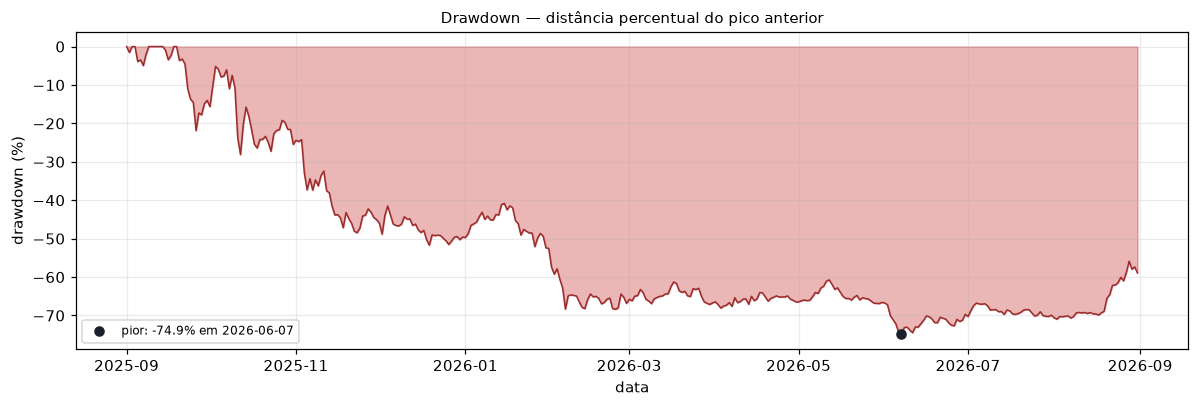

drawdown máximo: -74.9% em 2026-06-07
dias abaixo do pico: 354 de 365 (97% do período)
drawdown no último dia: -58.9%


In [5]:
pico = preco.cummax()
drawdown = preco / pico - 1

fig, eixo = plt.subplots(figsize=(11, 3.8))
eixo.fill_between(drawdown.index, drawdown.values * 100, 0,
                  color="#c53030", alpha=0.35)
eixo.plot(drawdown.index, drawdown.values * 100, color="#9b2c2c", linewidth=1)
eixo.scatter([drawdown.idxmin()], [drawdown.min() * 100], color="#1a202c",
             zorder=3, s=35, label=f"pior: {drawdown.min():.1%} em {drawdown.idxmin().date()}")
eixo.set_ylabel("drawdown (%)")
eixo.set_xlabel("data")
eixo.set_title("Drawdown — distância percentual do pico anterior", fontsize=10)
eixo.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"drawdown máximo: {drawdown.min():.1%} em {drawdown.idxmin().date()}")
print(f"dias abaixo do pico: {(drawdown < 0).sum()} de {len(drawdown)} "
      f"({(drawdown < 0).mean():.0%} do período)")
print(f"drawdown no último dia: {drawdown.iloc[-1]:.1%}")

### Interpretação

O drawdown máximo foi de **−74,9%** (07/06/2026): quem tivesse entrado no topo teria
visto três quartos do valor evaporarem. E a série passou **97% dos dias abaixo do
pico anterior** — só 11 dias de 365 estabeleceram máximas novas.

Isso explica um número que aparece nos atributos e pode confundir: `drawdown` tem
média de −62% na tabela de regimes. Não é erro — é a consequência de o pico do período
ter sido atingido logo no começo (set/2025) e nunca mais ser alcançado.

**Cuidado metodológico:** como o pico está quase todo no início, o `drawdown` é uma
variável de tendência longa, quase monotônica no período. Ele carrega pouca informação
diferencial para classificar o dia seguinte — coerente com ele ter ficado entre os
atributos de menor peso no modelo (contribuição de apenas +0,10 na previsão analisada).

---
## 5. Autocorrelação — direção *versus* magnitude

Esta é a análise mais importante do notebook. Ela compara duas perguntas:

1. **O retorno de hoje ajuda a prever o retorno de amanhã?** → autocorrelação de `ret`
2. **A magnitude de hoje ajuda a prever a magnitude de amanhã?** → autocorrelação de `|ret|`

A banda tracejada é o intervalo de ±1,96/√n: valores dentro dela são
indistinguíveis de zero.

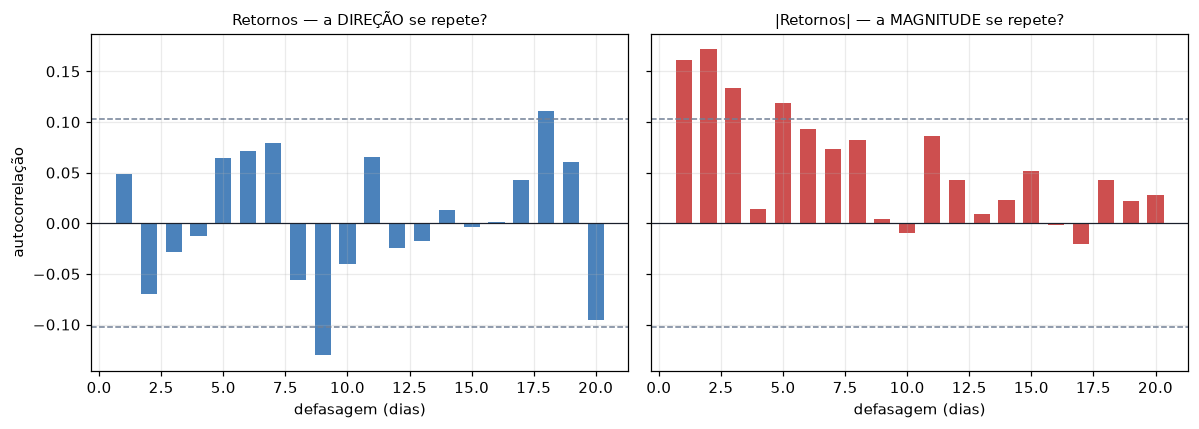

banda de significância: ±0.103
retornos   — lags significativos: [9, 18]  (2 de 20)
|retornos| — lags significativos: [1, 2, 3, 5]  (4 de 20)

primeiras defasagens:
  lag       ret     |ret|
    1     0.049     0.161
    2    -0.070     0.172
    3    -0.029     0.133
    4    -0.012     0.014
    5     0.065     0.118


In [6]:
LAGS = 20
banda = 1.96 / np.sqrt(len(ret))

acf_ret = [ret.autocorr(k) for k in range(1, LAGS + 1)]
acf_abs = [ret.abs().autocorr(k) for k in range(1, LAGS + 1)]
lags = np.arange(1, LAGS + 1)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for eixo, valores, titulo, cor in (
    (a, acf_ret, "Retornos — a DIREÇÃO se repete?", "#2b6cb0"),
    (b, acf_abs, "|Retornos| — a MAGNITUDE se repete?", "#c53030"),
):
    eixo.bar(lags, valores, color=cor, alpha=0.85, width=0.65)
    eixo.axhline(0, color="#1a202c", linewidth=0.8)
    eixo.axhline(banda, color="#718096", linestyle="--", linewidth=1)
    eixo.axhline(-banda, color="#718096", linestyle="--", linewidth=1)
    eixo.set_xlabel("defasagem (dias)")
    eixo.set_title(titulo, fontsize=10)
a.set_ylabel("autocorrelação")

fig.tight_layout()
plt.show()

sig_ret = [k for k in range(1, LAGS + 1) if abs(ret.autocorr(k)) > banda]
sig_abs = [k for k in range(1, LAGS + 1) if abs(ret.abs().autocorr(k)) > banda]
print(f"banda de significância: ±{banda:.3f}")
print(f"retornos   — lags significativos: {sig_ret}  ({len(sig_ret)} de {LAGS})")
print(f"|retornos| — lags significativos: {sig_abs}  ({len(sig_abs)} de {LAGS})")
print("\nprimeiras defasagens:")
print(f"{'lag':>5}{'ret':>10}{'|ret|':>10}")
for k in range(1, 6):
    print(f"{k:>5}{ret.autocorr(k):>10.3f}{ret.abs().autocorr(k):>10.3f}")

### Interpretação — o achado central do projeto

As duas metades do gráfico contam histórias opostas.

**Direção (esquerda): praticamente ruído branco.** Só 2 dos 20 lags saem da banda de
significância — e a 5% de significância, esperaríamos 1 por puro acaso. Não há
estrutura utilizável: saber que ontem subiu não diz nada de confiável sobre hoje.

**Magnitude (direita): estrutura clara e persistente.** As defasagens 1, 2, 3 e 5 são
todas positivas e significativas (0,161 / 0,172 / 0,133 / 0,118). Dias de movimento
grande são seguidos por dias de movimento grande. É o **agrupamento de volatilidade**
que a seção 3 mostrou visualmente, agora medido.

### Por que isso importa para o resto do projeto

Este resultado **prevê e explica** o desempenho da classificação:

- A tarefa escolhida (direção do dia seguinte) ataca justamente a dimensão onde a
  série **não tem sinal**. Ficar perto de 50% de acurácia não é falha de execução —
  é o que a estrutura do dado permite.
- A extensão sugerida para o Encontro 12 (**regressão de volatilidade futura**) ataca
  a dimensão onde a série **tem sinal**. A autocorrelação de |retornos| é a evidência
  empírica de que esse caminho é mais promissor.

Em outras palavras: a EDA, feita antes da modelagem, já antecipava o resultado — e é
por isso que ela vem antes.

---
## 6. Volume × retorno × volatilidade

O volume negociado costuma ser tratado como sinal. Vale separar duas hipóteses:
volume alto acompanha **movimento grande**, ou volume alto acompanha **alta**?

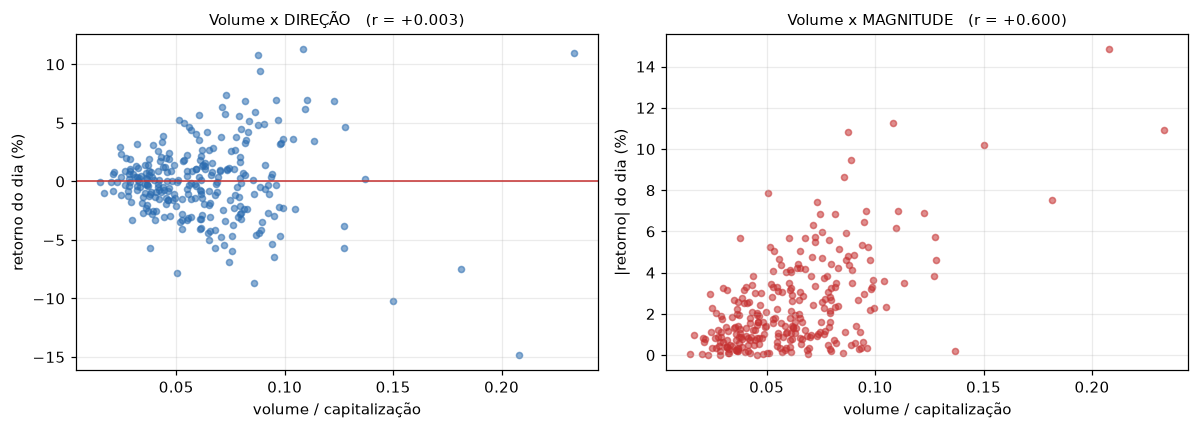

correlações com a razão volume/capitalização:
   retorno com sinal (direção) : +0.003
   |retorno| (magnitude)       : +0.600
   volatilidade de 30 dias     : +0.418


In [7]:
base = atributos[["razao_vol_cap", "ret_1d", "vol_30d"]].dropna().copy()
base["mov_abs"] = base["ret_1d"].abs()

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))

a.scatter(base["razao_vol_cap"], base["ret_1d"] * 100, s=16,
          color="#2b6cb0", alpha=0.55)
a.axhline(0, color="#c53030", linewidth=1)
a.set_xlabel("volume / capitalização")
a.set_ylabel("retorno do dia (%)")
a.set_title(f"Volume x DIREÇÃO   (r = {base['razao_vol_cap'].corr(base['ret_1d']):+.3f})",
            fontsize=10)

b.scatter(base["razao_vol_cap"], base["mov_abs"] * 100, s=16,
          color="#c53030", alpha=0.55)
b.set_xlabel("volume / capitalização")
b.set_ylabel("|retorno| do dia (%)")
b.set_title(f"Volume x MAGNITUDE   (r = {base['razao_vol_cap'].corr(base['mov_abs']):+.3f})",
            fontsize=10)

fig.tight_layout()
plt.show()

print("correlações com a razão volume/capitalização:")
print(f"   retorno com sinal (direção) : {base['razao_vol_cap'].corr(base['ret_1d']):+.3f}")
print(f"   |retorno| (magnitude)       : {base['razao_vol_cap'].corr(base['mov_abs']):+.3f}")
print(f"   volatilidade de 30 dias     : {base['razao_vol_cap'].corr(base['vol_30d']):+.3f}")

### Interpretação

O contraste é quase perfeito e reforça a seção 5 por um caminho independente:

| relação | correlação |
|---|---|
| volume × **direção** (retorno com sinal) | **+0,003** |
| volume × **magnitude** (\|retorno\|) | **+0,600** |
| volume × volatilidade de 30 dias | +0,418 |

A correlação com a direção é **0,003** — zero para todos os efeitos práticos. A nuvem
da esquerda é simétrica em torno do zero: volume alto acontece tanto em dias de alta
quanto de baixa.

Já a correlação com a magnitude é **+0,600**, forte. A nuvem da direita abre em forma
de funil: volume alto praticamente garante movimento grande, mas não diz para que lado.

**A mesma conclusão da autocorrelação, por outro caminho:** a série informa
*quanto*, não *para onde*. Dois indícios independentes apontando na mesma direção
dão bastante confiança ao diagnóstico.

---
## 7. Solana × Bitcoin — o BTC apenas como série de referência

O Bitcoin entra aqui **somente como referência de mercado**, para situar a Solana. Ele
não é modelado, não vira atributo e não entra em nenhuma etapa de aprendizado — o
projeto continua sendo de um único ativo.

Os dados vêm de `data/raw/bitcoin.json`, já coletado na mesma janela, sem nova
chamada à API.

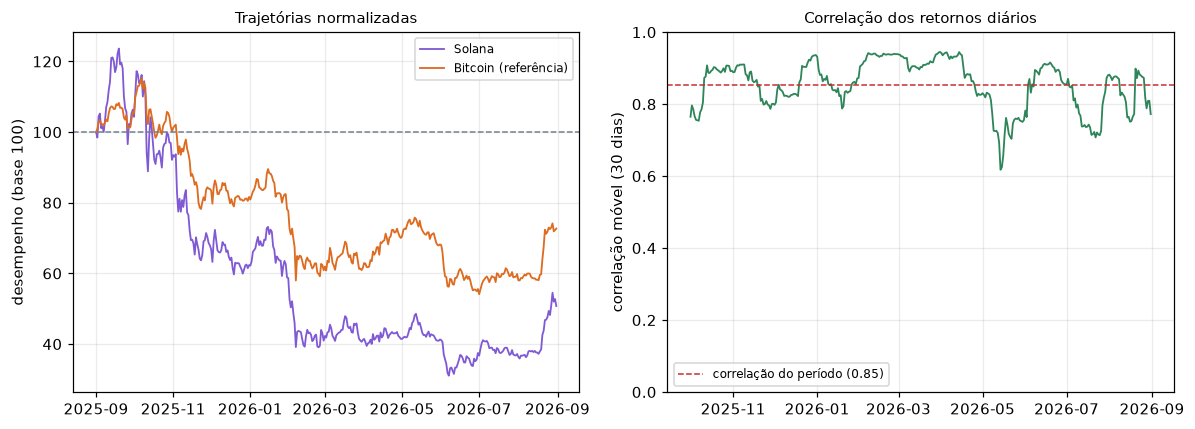

correlação dos retornos no período: +0.853
correlação móvel 30d — mín 0.62  mediana 0.87  máx 0.95

no período:  SOL -49.2%   BTC -27.3%
volatilidade diária:  SOL 3.55%   BTC 2.29%  (1.5x)


In [8]:
bruto_btc = json.loads((RAIZ / "data/raw/bitcoin.json").read_text())
btc = pd.Series(
    {pd.Timestamp(t, unit="ms").normalize(): v for t, v in bruto_btc["prices"]}
).sort_index()
ret_btc = (btc / btc.shift(1) - 1).dropna()

comum = ret.index.intersection(ret_btc.index)
r_sol, r_btc = ret[comum], ret_btc[comum]

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))

# desempenho normalizado (base 100) — compara trajetórias, não preços
a.plot(preco.index, preco / preco.iloc[0] * 100, color="#805ad5",
       linewidth=1.2, label="Solana")
a.plot(btc.index, btc / btc.iloc[0] * 100, color="#dd6b20",
       linewidth=1.2, label="Bitcoin (referência)")
a.axhline(100, color="#718096", linestyle="--", linewidth=1)
a.set_ylabel("desempenho (base 100)")
a.set_title("Trajetórias normalizadas", fontsize=10)
a.legend(fontsize=8)

corr_movel = r_sol.rolling(30).corr(r_btc)
b.plot(corr_movel.index, corr_movel.values, color="#2f855a", linewidth=1.2)
b.axhline(r_sol.corr(r_btc), color="#c53030", linestyle="--", linewidth=1,
          label=f"correlação do período ({r_sol.corr(r_btc):.2f})")
b.set_ylim(0, 1)
b.set_ylabel("correlação móvel (30 dias)")
b.set_title("Correlação dos retornos diários", fontsize=10)
b.legend(fontsize=8)

fig.tight_layout()
plt.show()

print(f"correlação dos retornos no período: {r_sol.corr(r_btc):+.3f}")
print(f"correlação móvel 30d — mín {corr_movel.min():.2f}  "
      f"mediana {corr_movel.median():.2f}  máx {corr_movel.max():.2f}")
print(f"\nno período:  SOL {preco.iloc[-1] / preco.iloc[0] - 1:+.1%}   "
      f"BTC {btc.iloc[-1] / btc.iloc[0] - 1:+.1%}")
print(f"volatilidade diária:  SOL {r_sol.std():.2%}   BTC {r_btc.std():.2%}  "
      f"({r_sol.std() / r_btc.std():.1f}x)")

### Interpretação

A correlação dos retornos diários é **+0,853** — muito alta. A correlação móvel de 30
dias fica entre 0,62 e 0,95 e nunca se aproxima de zero: a Solana se move
essencialmente junto com o mercado, sem períodos de descolamento real no intervalo
analisado.

Mas a **amplitude** difere: no mesmo período o BTC caiu 27,3% e a Solana, 49,2%. A
volatilidade diária da Solana também é maior. A Solana se comporta como uma versão
amplificada do mercado — mesma direção, movimento maior.

**Implicação para o projeto:** boa parte do que acontece com a Solana é movimento de
mercado, não característica idiossincrática do ativo. Isso limita o que atributos
construídos só a partir da própria série podem capturar — parte relevante da
informação é externa a ela.

---
## Síntese da EDA

| # | Análise | Achado |
|---|---|---|
| 1 | Preço (linear e log) | Período de queda: −49,2%; topo a fundo −74,9% |
| 2 | Distribuição dos retornos | Não normal (JB p≈9e-13); eventos de 4σ são 87x mais frequentes |
| 3 | Volatilidade no tempo | Varia >3x; agrupa em blocos que os regimes capturam |
| 4 | Drawdown | Máximo −74,9%; 97% dos dias abaixo do pico |
| 5 | Autocorrelação | **Direção ≈ ruído branco; magnitude persistente** |
| 6 | Volume | r=+0,003 com direção; **r=+0,600 com magnitude** |
| 7 | BTC (referência) | Correlação +0,853; Solana amplifica o mercado |

### A conclusão que atravessa tudo

Três análises independentes — autocorrelação (5), volume (6) e agrupamento de
volatilidade (3) — convergem para o mesmo diagnóstico:

> **A série carrega informação sobre a magnitude do movimento, quase nenhuma sobre
> a sua direção.**

Isso tem duas consequências diretas para o restante do projeto:

1. **Contextualiza a classificação.** O desempenho próximo de 50% obtido nos
   Encontros 10-11 não é falha de execução: a tarefa ataca a dimensão sem sinal. A
   EDA já antecipava esse resultado — e por isso ela vem antes da modelagem.

2. **Orienta a extensão (Encontro 12).** A regressão de volatilidade futura ataca a
   dimensão com sinal. As análises 3, 5 e 6 são a justificativa empírica dessa
   escolha, e não apenas uma preferência metodológica.

> **Lembrete.** Todas as observações descrevem o período coletado (set/2025 a
> ago/2026), marcado por queda acentuada. Nada aqui é recomendação de investimento.
